# Does a noise-trained NLE equal a noiseless NLE convolved with the errors?

## Why this test

The production NLE is trained with measurement noise injected: every
training star gets a random $\sigma_v$, Gaussian noise of that width is
added to its $v_{\rm los}$, and $\sigma_v$ is appended to the flow's
context. The model learns

$$p_{\rm noisy}(v_{\rm obs}\mid \log R,\, \theta,\, \log r_{1/2},\,
\sigma_v).$$

A second model is trained on the same simulations with no noise and no
$\sigma_v$ in its context:

$$p_{\rm clean}(v \mid \log R,\, \theta,\, \log r_{1/2}).$$

If both flows are faithful, the first is the second convolved with the
error kernel,

$$p_{\rm noisy}(v_{\rm obs}\mid\sigma_v) = \int p_{\rm clean}(v)\,
\mathcal N(v_{\rm obs};\, v,\, \sigma_v^2)\, {\rm d}v ,$$

for every $\sigma_v$ and every context. Two reasons to check it:

1. It is the paper's demonstration that the noise augmentation is learned
   consistently with the physics (the model does not use $\sigma_v$ as a
   shortcut).
2. Real errors need not be Gaussian. The noiseless model is the one that
   lets an arbitrary per-star kernel be applied at inference; the
   convolution below is that machinery.

**Models.** Both trained on shards 0-1 (190k galaxies), T2 architecture
(NSF 4x[128,128], 8 bins, context MLP to 64), 30k steps at batch 16384:
`errtest_clean` = run `voj63drr`, `errtest_noisy` = run `6xaw28uw`
(`configs/nle_8p_v4_errtest.py`).

In [1]:
# Paths and imports.
import math
import os
import sys
import time
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))                            # nle_dsph package
sys.path.insert(0, os.path.expanduser('~/my_modules'))   # dsph_analysis
os.chdir(ROOT)

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from IPython.display import display

from nle import NLE                  # Lightning module: flow + normalisation
from transforms import StarBatch     # the per-star container the model reads
from diagnostics.pit_by_regime import best_checkpoint, load_shard

pd.set_option('display.width', 200)
pd.set_option('display.max_columns', 30)
dev = 'cuda' if torch.cuda.is_available() else 'cpu'

MODELS = Path(os.path.expanduser(
    '~/scratch/projects/sbi_dsph/trained_models/nle/nle_8p_ZhaoPlumCOM_v4'))
OUT = Path(os.path.expanduser('~/scratch/projects/nle_dsph'))
LABELS = ('dm_alpha', 'dm_beta', 'dm_gamma', 'dm_log_rdm', 'dm_log_rho0',
          'df_beta0', 'df_log_ra')

%matplotlib inline
# plt.style.use('~/default.mplstyle')

In [2]:
clean = NLE.load_from_checkpoint(
    best_checkpoint(MODELS / 'voj63drr'), map_location=dev,
    pre_transforms=None).eval()
noisy = NLE.load_from_checkpoint(
    best_checkpoint(MODELS / '6xaw28uw'), map_location=dev,
    pre_transforms=None).eval()

# The one structural difference: `vel_error` is in the noisy model's
# context and absent from the clean one's.
print('clean  target', clean.target_fields, ' context', clean.context_fields)
print('noisy  target', noisy.target_fields, ' context',
      noisy.context_fields)

[NLE] Context MLP 9 -> 64 with 26,048 parameters
[NLE] Modeling p(vel | pos,theta,cond)
[NLE] Flow built with 111,196 parameters
[NLE] Context MLP 10 -> 64 with 26,176 parameters
[NLE] Modeling p(vel | pos,theta,cond,vel_error)
[NLE] Flow built with 111,196 parameters
clean  target ['vel']  context ['pos', 'theta', 'cond']
noisy  target ['vel']  context ['pos', 'theta', 'cond', 'vel_error']


## 1. Units: the flow's density is per *normalised* velocity

`NLE.log_prob` returns $\log p$ per unit of the normalised velocity
$\tilde v = (v - v_{\rm loc}) / v_{\rm scale}$, and each model has its own
`vel_scale` (the half-range of the training velocities after noise). To
compare the two, or to feed either to a sampler alongside anything in
km/s, subtract $\log v_{\rm scale}$:

$$\log p(v)\,[{\rm per\ km/s}] = \log p(\tilde v) - \log v_{\rm scale}.$$

Forgetting this gives a constant offset of $\log(v_{\rm scale,noisy} /
v_{\rm scale,clean})$ nats per star that looks like a model disagreement
(it was the first thing this test "found").

In [3]:
ratio = float(noisy.vel_scale[0]) / float(clean.vel_scale[0])
print(f'vel_scale  clean {float(clean.vel_scale[0]):.2f}  '
      f'noisy {float(noisy.vel_scale[0]):.2f} km/s  ->  '
      f'log ratio {math.log(ratio):.4f} nats/star')


def logp_kms(model, R, v, err, theta, lrs):
    """Per-star log p in units of 1/(km/s).

    Args:
        model: A trained NLE.
        R: Projected radii [kpc], shape (n,). Only |pos| enters the
            context with `condition_on_radius`.
        v: Velocities to evaluate at [km/s], shape (n,).
        err: sigma_v [km/s], shape (n,), or None for the clean model.
        theta: Labels, shape (n, 7), radii in units of r_half.
        lrs: log10 r_half [kpc].

    Returns:
        Tensor of shape (n,).
    """
    n = len(R)
    pos = torch.zeros((n, 2), device=dev)
    pos[:, 0] = R
    batch = StarBatch(
        pos=pos, vel=v.view(n, 1),
        vel_error=None if err is None else err.view(n, 1),
        theta=theta, cond=torch.full((n, 1), lrs, device=dev))
    with torch.no_grad():
        return model.log_prob(batch) - torch.log(model.vel_scale[0])

vel_scale  clean 193.76  noisy 205.21 km/s  ->  log ratio 0.0574 nats/star


## 2. One star, by eye

Take one held-out galaxy (shard 40 was never used in training), one of
its stars, and a chosen $\sigma_v$. Plot $p_{\rm clean}(v)$, its
numerical convolution with $\mathcal N(0, \sigma_v^2)$ on a fine grid,
and $p_{\rm noisy}(v_{\rm obs} \mid \sigma_v)$ evaluated directly. The
dashed curve should sit on the shaded one.

In [4]:
# (pos, vel) per star; (th, lrs, n) per galaxy
pos, vel, th, lrs_all, n = load_shard(40, n_gal=50)

g = 3                                        # which galaxy
sl = slice(int(n[:g].sum()), int(n[:g + 1].sum()))
R = pos[sl, :2].norm(dim=1).to(dev)          # projection along z
v_true = vel[sl, 2].to(dev)                  # true line-of-sight velocity
theta = th[g].expand(len(R), 7).to(dev)      # a galaxy's stars share theta
lrs = float(lrs_all[g])
sig_true = float(v_true.std())

i, sigma = 0, 5.0                            # star index, error [km/s]
n_grid = 1201
vg = torch.linspace(-30, 30, n_grid, device=dev)
R_i = R[i].expand(n_grid)
theta_i = theta[:1].expand(n_grid, 7)
err_i = torch.full((n_grid,), sigma, device=dev)

p_clean = torch.exp(logp_kms(clean, R_i, vg, None, theta_i, lrs)).cpu()
p_noisy = torch.exp(logp_kms(noisy, R_i, vg, err_i, theta_i, lrs)).cpu()

# Direct convolution on the grid:
# p_conv(v_obs) = sum_v p_clean(v) N(v_obs; v, sigma) dv
vgc = vg.cpu()
dv = float(vgc[1] - vgc[0])
kern = torch.exp(-0.5 * ((vgc[:, None] - vgc[None, :]) / sigma) ** 2)
kern /= sigma * math.sqrt(2 * math.pi)
p_conv = (kern * p_clean[None, :]).sum(1) * dv

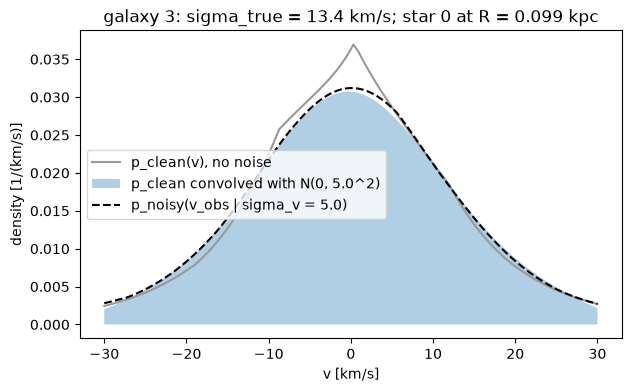

In [5]:
plt.figure(figsize=(7, 4))
plt.plot(vgc, p_clean, color='0.6', label='p_clean(v), no noise')
plt.fill_between(vgc, p_conv, alpha=0.35,
                 label=f'p_clean convolved with N(0, {sigma}^2)')
plt.plot(vgc, p_noisy, 'k--', label=f'p_noisy(v_obs | sigma_v = {sigma})')
plt.xlabel('v [km/s]')
plt.ylabel('density [1/(km/s)]')
plt.title(f'galaxy {g}: sigma_true = {sig_true:.1f} km/s; '
          f'star {i} at R = {float(R[i]):.3f} kpc')
plt.legend()
plt.show()

## 3. The convolution for many stars at once

For a quantitative comparison we need the convolved density at every
star's observed velocity. The integrand $p_{\rm clean}(v)\,\mathcal
N(v_{\rm obs}; v, \sigma_v)$ is only non-negligible where *both* factors
are:

* the intrinsic peak lives in $|v| \lesssim 12\,\sigma_{\rm true}$,
* the kernel in $v_{\rm obs} \pm 8\sigma_v$.

The grid spans the **intersection** of the two, so it resolves whichever
is narrower: a 0.1 km/s galaxy under 10 km/s errors, or a 20 km/s galaxy
with 0.3 km/s errors. (Gridding the union instead left 0.4 nats/star of
quadrature error in the first case.) The sum is a trapezoid rule done in
log space with `logsumexp` so very small densities do not underflow.

In [6]:
def convolved_logp(R, v_obs, sigma, sig_true, theta, lrs, n_grid=257):
    """log Int p_clean(v) N(v_obs; v, sigma) dv per star, in 1/(km/s).

    Args:
        R: Projected radii [kpc], shape (n,).
        v_obs: Observed velocities [km/s], shape (n,).
        sigma: The error [km/s], one value for all stars.
        sig_true: Intrinsic dispersion of each star's galaxy, shape (n,).
        theta: Labels, shape (n, 7).
        lrs: log10 r_half [kpc].
        n_grid: Trapezoid nodes per star (accuracy/cost, section 5).

    Returns:
        Tensor of shape (n,).
    """
    lo = torch.maximum(v_obs - 8 * sigma, -12 * sig_true)
    hi = torch.minimum(v_obs + 8 * sigma, 12 * sig_true)
    hi = torch.maximum(hi, lo + 1e-3)        # guard: empty overlap
    t = torch.linspace(0, 1, n_grid, device=dev)
    grid = lo[:, None] + (hi - lo)[:, None] * t[None, :]   # (n, n_grid)
    n = len(v_obs)
    # One batched forward pass over all (star, node) pairs.
    lp = logp_kms(clean, R.repeat_interleave(n_grid), grid.reshape(-1),
                  None, theta.repeat_interleave(n_grid, 0), lrs)
    lp = lp.view(n, n_grid)
    lk = (-0.5 * ((v_obs[:, None] - grid) / sigma) ** 2
          - math.log(sigma * math.sqrt(2 * math.pi)))
    w = torch.zeros_like(lp)
    w[:, [0, -1]] = math.log(0.5)            # trapezoid end weights
    return (torch.logsumexp(lp + lk + w, dim=1)
            + torch.log((hi - lo) / (n_grid - 1)))


# d = log p_noisy - log(convolved p_clean), per star, at the true theta
st = torch.full_like(v_true, sig_true)
for sigma in (0.3, 1.0, 3.0, 10.0):
    torch.manual_seed(0)
    v_obs = v_true + sigma * torch.randn_like(v_true)
    err = torch.full_like(v_obs, sigma)
    d = (logp_kms(noisy, R, v_obs, err, theta, lrs)
         - convolved_logp(R, v_obs, sigma, st, theta, lrs))
    print(f'sigma_v = {sigma:5.1f} km/s:  per star  mean {d.mean():+.4f}  '
          f'rms {d.pow(2).mean().sqrt():.4f}   |  summed over the galaxy '
          f'({len(d)} stars) {d.sum():+.2f} nats')

sigma_v =   0.3 km/s:  per star  mean +0.0007  rms 0.0748   |  summed over the galaxy (98 stars) +0.07 nats
sigma_v =   1.0 km/s:  per star  mean +0.0011  rms 0.0970   |  summed over the galaxy (98 stars) +0.11 nats
sigma_v =   3.0 km/s:  per star  mean +0.0010  rms 0.0864   |  summed over the galaxy (98 stars) +0.10 nats
sigma_v =  10.0 km/s:  per star  mean +0.0026  rms 0.0794   |  summed over the galaxy (98 stars) +0.26 nats


\
**Reading it.** The per-star mean of $d$ is at the $10^{-3}$ level and
the galaxy sum below a nat. The rms per star (a few $\times 10^{-2}$) is
the *combined* approximation error of two independently trained flows
plus the quadrature; it adds up incoherently over a galaxy ($\sqrt N$),
which is why the galaxy sum stays small. For the posterior what matters
is the galaxy-level error, since every star is evaluated at the same
$\theta$.

## 4. The batch result (3000 galaxies, four $\sigma_v$)

`diagnostics/check_error_convolution.py` runs the same comparison on
3000 galaxies of shard 40 and also against the 5-shard T2 model
(`noisy2`). Columns: `sigma` the assumed error (km/s); `sig_lo`-`sig_hi`
the bin of the galaxy's intrinsic dispersion (km/s); `star_*` statistics
of $d$ per star; `gal_*` of $d$ summed over a galaxy; `nll_*` the mean
negative log density of each side. The figure scans $\log L$ in
`dm_log_rho0` for six galaxies with the other labels at the truth: the
three curves should coincide.

In [7]:
csv = sorted((MODELS / 'voj63drr').glob('error_convolution_*v2.csv'))
batch = pd.read_csv(csv[-1])
display(batch.round(4))

,model,sigma,sig_lo,sig_hi,n_stars,n_gal,star_mean,star_rms,star_p99,gal_mean,gal_rms,gal_p99,nll_noisy,nll_conv
0,noisy,0.3,0,1,98445,1000,-0.0057,0.1385,0.5436,-0.5648,1.9458,7.5283,0.6273,0.6215
1,noisy,0.3,1,3,59141,605,0.0016,0.1048,0.3899,0.1583,1.1464,3.8987,1.9091,1.9108
2,noisy,0.3,3,10,76467,774,0.0023,0.1056,0.3997,0.2246,1.0693,2.9698,3.0453,3.0476
3,noisy,0.3,10,40,61305,621,0.0036,0.1171,0.4063,0.3519,1.2246,3.8041,4.1329,4.1364
4,noisy2,0.3,0,1,98445,1000,-0.0020,0.1163,0.3959,-0.1974,1.2166,3.9954,0.6235,0.6215
5,noisy2,0.3,1,3,59141,605,0.0039,0.1036,0.3531,0.3849,1.1132,3.4280,1.9068,1.9108
6,noisy2,0.3,3,10,76467,774,0.0041,0.1010,0.3742,0.4063,1.1159,3.2488,3.0435,3.0476
7,noisy2,0.3,10,40,61305,621,0.0053,0.1168,0.4071,0.5206,1.3668,4.4532,4.1311,4.1364
8,noisy,1.0,0,1,98445,1000,-0.0032,0.0867,0.3190,-0.3196,1.0422,3.3627,1.5023,1.4990
9,noisy,1.0,1,3,59141,605,-0.0007,0.0983,0.3603,-0.0652,0.9967,3.0296,2.1013,2.1007


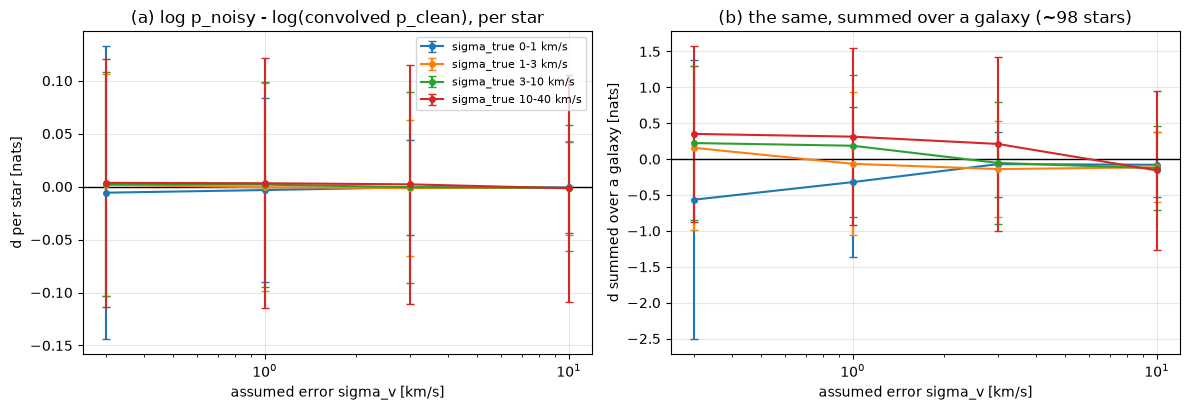

In [8]:
# Same numbers as the table, drawn here rather than loaded as an image.
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
sub = batch[batch.model == 'noisy']
for (lo, hi), grp in sub.groupby(['sig_lo', 'sig_hi']):
    lab = f'sigma_true {lo:g}-{hi:g} km/s'
    ax[0].errorbar(grp.sigma, grp.star_mean, yerr=grp.star_rms, fmt='o-',
                   capsize=3, ms=4, label=lab)
    ax[1].errorbar(grp.sigma, grp.gal_mean, yerr=grp.gal_rms, fmt='o-',
                   capsize=3, ms=4)
for a in (ax[0], ax[1]):
    a.axhline(0, color='k', lw=1)
    a.set_xscale('log')
    a.set_xlabel('assumed error sigma_v [km/s]')
    a.grid(alpha=0.3)
ax[0].set(ylabel='d per star [nats]',
          title='(a) log p_noisy - log(convolved p_clean), per star')
ax[1].set(ylabel='d summed over a galaxy [nats]',
          title='(b) the same, summed over a galaxy (~98 stars)')
ax[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

The quantity that actually matters is the galaxy-level
log-likelihood as a function of $\theta$, since that is what the sampler
sees. Scan one label with the others held at the truth and compare the
noisy model against the convolved clean model. A constant offset between
the curves is harmless; a difference in shape is not.

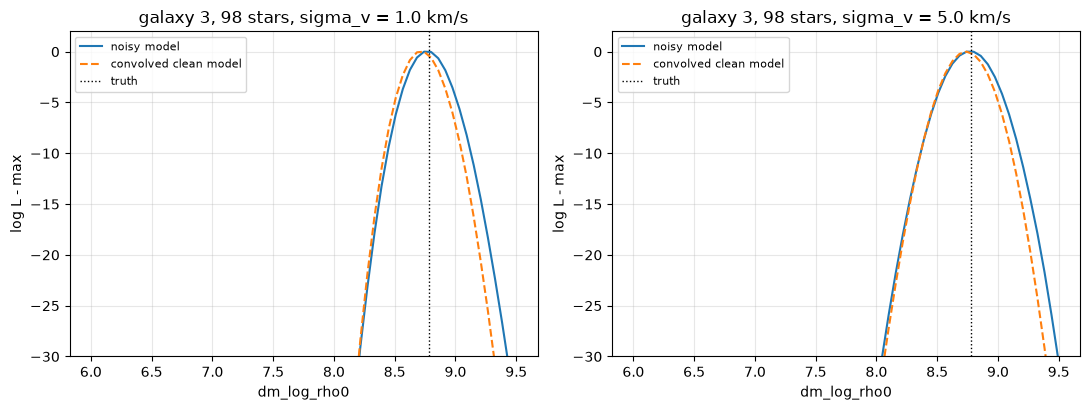

In [9]:
k = LABELS.index('dm_log_rho0')
scan = torch.linspace(6.0, 9.5, 61)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for a, sigma in zip(axes, (1.0, 5.0)):
    torch.manual_seed(0)
    v_obs = v_true + sigma * torch.randn_like(v_true)
    err = torch.full_like(v_obs, sigma)
    ll_noisy, ll_conv = [], []
    for val in scan:
        tt = theta.clone()
        tt[:, k] = val
        ll_noisy.append(float(logp_kms(noisy, R, v_obs, err, tt, lrs).sum()))
        ll_conv.append(float(convolved_logp(R, v_obs, sigma, st, tt, lrs).sum()))
    ll_noisy = np.array(ll_noisy)
    ll_conv = np.array(ll_conv)
    a.plot(scan, ll_noisy - ll_noisy.max(), '-', label='noisy model')
    a.plot(scan, ll_conv - ll_conv.max(), '--', label='convolved clean model')
    a.axvline(float(th[g, k]), color='k', ls=':', lw=1, label='truth')
    a.set(ylim=(-30, 2), xlabel='dm_log_rho0', ylabel='log L - max',
          title=f'galaxy {g}, {len(R)} stars, sigma_v = {sigma} km/s')
    a.grid(alpha=0.3)
    a.legend(fontsize=8)
fig.tight_layout()
plt.show()

## 5. What the noiseless route costs

Each convolved evaluation is `n_grid` forward passes of the clean model,
so its cost relative to one noisy-model evaluation is about
$1.1 \times$ `n_grid`. The accuracy floor worth reaching is the
model-to-model scatter above (about 1 nat per galaxy): 65 nodes get
there, 129 are well below it. The kernel shape does not change this; a
heavy-tailed kernel only widens the grid.

In [10]:
sigma = 1.0
torch.manual_seed(0)
v_obs = v_true + sigma * torch.randn_like(v_true)
err = torch.full_like(v_obs, sigma)
ref = convolved_logp(R, v_obs, sigma, st, theta, lrs, n_grid=1025)


def timeit(f, reps=5):
    """Mean wall time of f() over `reps` calls after one warm-up."""
    f()
    torch.cuda.synchronize()
    t0 = time.time()
    for _ in range(reps):
        f()
    torch.cuda.synchronize()
    return (time.time() - t0) / reps


t_noisy = timeit(lambda: logp_kms(noisy, R, v_obs, err, theta, lrs))
print(f'{"n_grid":>7} {"time / noisy":>13} '
      f'{"rms error vs 1025 nodes [nats/star]":>38}')
for ng in (17, 33, 65, 129, 257):
    conv = lambda: convolved_logp(R, v_obs, sigma, st, theta, lrs,
                                  n_grid=ng)
    t = timeit(conv, reps=2)
    rms = float((conv() - ref).pow(2).mean().sqrt())
    print(f'{ng:>7} {t / t_noisy:>12.1f}x {rms:>38.4f}')

 n_grid  time / noisy    rms error vs 1025 nodes [nats/star]
     17          1.1x                                 0.0005
     33          1.1x                                 0.0001
     65          1.0x                                 0.0000
    129          1.8x                                 0.0000
    257          3.0x                                 0.0000
